# Remote Sensing Workflow

## Imports

In [530]:
# GIS and spatial data libraries
import rasterio
from rasterio.plot import show
from rasterio.transform import xy
from rasterio.warp import reproject, Resampling, transform_bounds

import pyproj
from pyproj import Transformer

from affine import Affine
from osgeo import gdal
from shapely.geometry import box

# Data analysis and machine learning libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from itertools import combinations
from scipy.stats import skew
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Data access libraries
import ee
import requests

import json
import os
import pip
import platform

from pathlib import Path
from IPython.display import Image, display

# Check for load errors
print(
    "All libraries imported successfully\n" 
    f"gdal v.{gdal.__version__}\n"
    f"pip v.{pip.__version__}\n"
    f"Python v{platform.python_version()}"
)

All libraries imported successfully
gdal v.3.13.3
pip v.25.2
Python v3.13.7


In [532]:
# Verify paths
print(
    f"Working directory: {Path.cwd()}\n" 
    f"Python executable: {os.sys.executable}\n"
    f"Datasets folder exists: {Path("Datasets").exists()}\n"
    f"Datasets folder exists: {Path("Assets").exists()}\n"
)

Working directory: c:\Users\matil\Documents\GitHub\GIS-Project
Python executable: c:\Users\matil\AppData\Local\Programs\Python\Python313\python.exe
Datasets folder exists: True
Datasets folder exists: True



## Data Validation and Analysis

### OpenTopography DEM

In [533]:
# Load DEM raster and metadata
DEM_path = r"Datasets\opentopography\DEM.tif"

with rasterio.open(DEM_path) as DEM_src:

    elevation = DEM_src.read(1)
    elevation_transform = DEM_src.transform
    elevation_crs = DEM_src.crs
    elevation_nodata = DEM_src.nodata

    DEM_metadata = {
        "File Name": os.path.basename(DEM_path),
        "Type": type(elevation).__name__,
        "Size": elevation.size,
        "Shape": elevation.shape,
        "Max": elevation.max(),
        "Min": elevation.min(),
        "NoData": DEM_src.nodata,
        "CRS": DEM_src.crs, 
        "Resolution": DEM_src.res,
        "Bounds": DEM_src.bounds
    }

DEM_metadata

{'File Name': 'DEM.tif',
 'Type': 'ndarray',
 'Size': 596070,
 'Shape': (895, 666),
 'Max': np.float32(1503.917),
 'Min': np.float32(-32767.0),
 'NoData': -32767.0,
 'CRS': CRS.from_wkt('PROJCS["NAD83(CSRS) / Canada Atlas Lambert",GEOGCS["NAD83(CSRS)",DATUM["NAD83_Canadian_Spatial_Reference_System",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6140"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4617"]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",49],PARAMETER["central_meridian",-95],PARAMETER["standard_parallel_1",49],PARAMETER["standard_parallel_2",77],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","3979"]]'),
 'Resolution': (30.0, 30.0),
 'Bounds': BoundingBox(left=-1980000.0, bottom=473550.0, right=-1960020.0, top=500400.0)}

In [534]:
# Transform DEM bounds
bounds_EPSG_4326 = transform_bounds(
    DEM_src.crs,
    "EPSG:4326",
    *DEM_src.bounds
)

bounds_EPSG_32610 = transform_bounds(
    DEM_src.crs,
    "EPSG:32610",
    *DEM_src.bounds
)

print(
    f"DEM export EPSG:3979: {tuple(DEM_src.bounds)}\n"
    f"EPSG:4326: {bounds_EPSG_4326 }\n"
    f"EPSG:32610: {bounds_EPSG_32610}" 
)

DEM export EPSG:3979: (-1980000.0, 473550.0, -1960020.0, 500400.0)
EPSG:4326: (-123.29291260026993, 49.25527457420543, -122.8853009908351, 49.55076853448343)
EPSG:32610: (478779.52998752374, 5455842.720256816, 508333.4824226063, 5488685.934225603)


In [535]:
# Bound Selection for AOI
transformer = pyproj.Transformer.from_crs("EPSG:32610", "EPSG:4326", always_xy=True)

xmin_geo, ymin_geo = transformer.transform(bounds_EPSG_32610[0], bounds_EPSG_32610[1])
xmax_geo, ymax_geo = transformer.transform(bounds_EPSG_32610[2], bounds_EPSG_32610[3])

print(
    f"xmin/W:: {xmin_geo}", 
    f"ymin/S: {ymin_geo}", 
    f"xmax/E: {xmax_geo}", 
    f"ymax/N: {ymax_geo}"
)

geometry = box(xmin_geo, ymin_geo, xmax_geo, ymax_geo)

geojson = {
    "type": "FeatureCollection",
    "features": [{
        "type": "Feature",
        "properties": {},
        "geometry": geometry.__geo_interface__
    }]
}

output_geojson_path = Path("Assets") / "dem_AOI.geojson"
with output_geojson_path.open("w", encoding="utf-8") as f:
    json.dump(geojson, f, indent=2)

xmin/W:: -123.29161663788408 ymin/S: 49.25498431356825 xmax/E: -122.88478957342635 ymax/N: 49.55071922714218


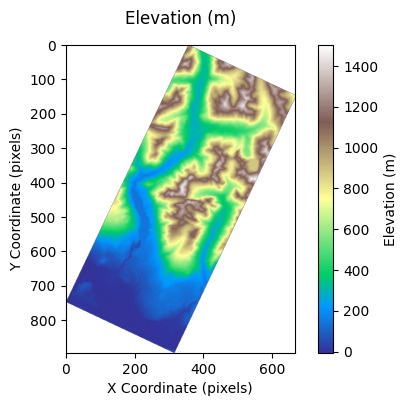

In [536]:
# NoData Mask
valid_mask = elevation != DEM_src.nodata

elevation_valid = np.where(
    valid_mask,
    elevation,
    np.nan
)

# Data visualization
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
image = ax.imshow(elevation_valid, cmap="terrain")
fig.colorbar(image, ax=ax, label="Elevation (m)")
ax.set_title("Elevation (m)", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### DEM, Sentinel, and Dynamic World V1 Data Load

#### Load Sentinel Data

In [ ]:
# Load sentinel bands and metadata 
def get_composite_data(ndvi_data_path):

    with rasterio.open(ndvi_data_path) as sentinel_src:

        bands = {
            "B4": sentinel_src.read(1),
            "B3": sentinel_src.read(2),
            "B2": sentinel_src.read(3),
            "B8_NIR": sentinel_src.read(4),
            "nd": sentinel_src.read(5),
        }

        raster_info = {
            "crs": sentinel_src.crs,
            "transform": sentinel_src.transform,
            "nodata": sentinel_src.nodatavals[0],
            "shape": sentinel_src.shape,
        }

        composite_metadata = {
            "File Name": os.path.basename(sentinel_src.name),
            "CRS": sentinel_src.crs,
            "Bounds": sentinel_src.bounds,
            "Width": sentinel_src.width,
            "Height": sentinel_src.height,
            "Tags": sentinel_src.tags(),
            "Resolution": sentinel_src.res,
            "NoData values": sentinel_src.nodatavals,
            "Transform": sentinel_src.transform,
            "Descriptions": sentinel_src.descriptions,
            "B4 Min/Max": (bands["B4"].min(), bands["B4"].max()),
            "B8 Min/Max": (bands["B8_NIR"].min(), bands["B8_NIR"].max()),
            "B2 Min/Max": (bands["B2"].min(), bands["B2"].max()),
            "B3 Min/Max": (bands["B3"].min(), bands["B3"].max()),
            "NDVI Min/Max": (bands["nd"].min(), bands["nd"].max()),       
        }

    return {
        "bands": bands,
        "raster_info": raster_info, 
        "metadata": composite_metadata,
    }

In [ ]:
# Load clean sentinel NDVI
def get_ndvi(ndvi_data_path):
    dataset = get_composite_data(ndvi_data_path)
    nd_band = dataset["bands"]["nd"]
    no_data_value = dataset["raster_info"]["nodata"]

    if no_data_value is None or np.isnan(no_data_value):
        no_data_mask = np.isfinite(nd_band)
    else:
        no_data_mask = ((nd_band != no_data_value) & np.isfinite(nd_band))

    dataset_clean = np.where(no_data_mask, nd_band, np.nan)
    
    return dataset_clean

#### DEM Reproject

In [ ]:
# Sample sentinel metadata for reproject parameters
reproject_sample_path = r"Datasets\sentinel_2_l2a\sentinel_l2a_202608_10UDV_composite.tif"

sentinel_shape = (get_composite_data(reproject_sample_path))["raster_info"]["shape"]
sentinel_transform = (get_composite_data(reproject_sample_path))["raster_info"]["transform"]
sentinel_crs = (get_composite_data(reproject_sample_path))["raster_info"]["crs"]

In [ ]:
# Reproject DEM onto sentinel grid
elevation_reproject = np.empty(sentinel_shape, dtype=np.float32)

reproject(
    source=elevation_valid,
    destination=elevation_reproject,
    src_transform=elevation_transform,
    src_crs=elevation_crs,
    dst_transform=sentinel_transform,
    dst_crs=sentinel_crs,
    dst_nodata=np.nan,
    shape=sentinel_shape,
    resampling=Resampling.bilinear
)

print(f"DEM Reproject shape: {elevation_reproject.shape}")

In [ ]:
# Crop DEM reproject 
valid_DEM = np.isfinite(elevation_reproject)
rows, cols = np.where(valid_DEM)

if rows.size == 0:
    raise ValueError("elevation_reproject contains no finite data")

row0, row1 = rows.min(), rows.max() + 1  
col0, col1 = cols.min(), cols.max() + 1
elevation_crop = elevation_reproject[row0:row1, col0:col1]

print(f"DEM crop shape: {elevation_crop.shape}")

In [ ]:
# Data visualization
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
im = ax.imshow(elevation_crop, cmap="terrain")
cbar = fig.colorbar(im, ax=ax, label="Elevation (m)")
ax.set_title("Elevation Reprojected to Sentinel-2 Grid", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

#### GDAL Slope

In [ ]:
# Create a GDAL in-memory dataset for the cropped DEM
dem_array = elevation_crop.astype(np.float32)
rows, cols = dem_array.shape

print("Rows:", rows)
print("Columns:", cols)

driver = gdal.GetDriverByName("MEM")
ds = driver.Create(
    "",
    cols,
    rows,
    1,
    gdal.GDT_Float32
)

# Translate the GDAL geotransform to match the cropped DEM's in sentinel grid
crop_transform = sentinel_transform * Affine.translation(col0, row0)
ds.SetGeoTransform(crop_transform.to_gdal())
ds.SetProjection(sentinel_crs.to_wkt())

band = ds.GetRasterBand(1)
band.WriteArray(dem_array)
band.SetNoDataValue(np.nan)

slope_ds = gdal.DEMProcessing(
    "",
    ds,
    "slope",
    format="MEM",
    slopeFormat="degree",
    alg="Horn"
)

slope_band = slope_ds.GetRasterBand(1)
slope_gdal_array = slope_band.ReadAsArray()
slope_gdal_array = np.where(
    slope_gdal_array == -9999,
    np.nan,
    slope_gdal_array
)

In [ ]:
# Data visualization
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
im = ax.imshow(slope_gdal_array, cmap="RdYlGn")
cbar = fig.colorbar(im, ax=ax, label="Slope (°)")
ax.set_title("Slope (°)", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

#### Sentinel Data Clean

In [ ]:
# Prepare clean sentinel datasets
sentinel_ndvi_datasets = []
years = range(2024, 2027)

for i in years:
    tif_path = rf"Datasets\sentinel_2_l2a\sentinel_l2a_{i}08_10UDV_composite.tif"
    sentinel_ndvi_datasets.append(get_ndvi(tif_path))

    metadata = get_composite_data(tif_path)
    print(metadata)

In [ ]:
# Crop sentinel
crop = (slice(row0, row1), slice(col0, col1))
ndvi_crop = []

for sentinel_ndvi_dataset in sentinel_ndvi_datasets:
    dataset_crop = sentinel_ndvi_dataset[crop]
    ndvi_crop.append(dataset_crop)

In [ ]:
# Data visualization
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=100, layout="constrained")

for ax, year, ndvi_data in zip(axes, years, ndvi_crop):
    image = ax.imshow(ndvi_data, cmap="RdYlGn", vmin=-1, vmax=1) 
    ax.set_title(f"NDVI {year}", pad=15)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

fig.colorbar(image, ax=axes, label="NDVI")
plt.show()

#### Dynamic World V1 Data

In [ ]:
# Load DWV1 bands and metadata 
dynamic_world_tif_path = r"Datasets\dynamic_world_V1\dynamic_world_20260807_T10UDV.tif"

with rasterio.open(dynamic_world_tif_path) as dw_src:
    dw_data = dw_src.read(1)
    dw_crs = dw_src.crs
    dw_transform = dw_src.transform
    dw_shape = dw_src.shape
    dw_nodata

    dw_metadata = {
        "File Name": os.path.basename(dw_src.name),
        "CRS": dw_src.crs,
        "Bounds": dw_src.bounds,
        "Width": dw_src.width,
        "Height": dw_src.height,
        "Tags": dw_src.tags(),
        "Resolution": dw_src.res,
        "NoData values": dw_src.nodatavals,
        "Transform": dw_src.transform,
    }

dw_metadata

{'File Name': 'dynamic_world_20260807_T10UDV.tif',
 'CRS': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 10N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32610"]]'),
 'Bounds': BoundingBox(left=478770.0, bottom=5455800.0, right=508390.0, top=5488730.0),
 'Width': 2962,
 'Height': 3293,
 'Tags': {'AREA_OR_POINT': 'Area'},
 'Resolution': (10.0, 10.0),
 'NoData values': (255.0,),
 'Transform': Affine(10.0, 0.0, 478770.0,
        0.0, -10.0, 5488730.0)}

In [ ]:
# Reproject DWV1 onto sentinel grid
dw_mask = dw_data != dw_nodata
dw_clean = np.where()
dw_reproject = np.empty(sentinel_shape, dtype=np.float32)

reproject(
    source=dw_data,
    destination=dw_reproject,
    src_transform=dw_transform,
    src_crs=dw_crs,
    dst_transform=sentinel_transform,
    dst_crs=sentinel_crs,
    dst_nodata=np.nan,
    shape=sentinel_shape,
    resampling=Resampling.nearest
)

dw_crop = dw_reproject[crop]

print(f"DWV1 Reproject shape: {dw_reproject.shape}")

DWV1 Reproject shape: (3293, 2962)


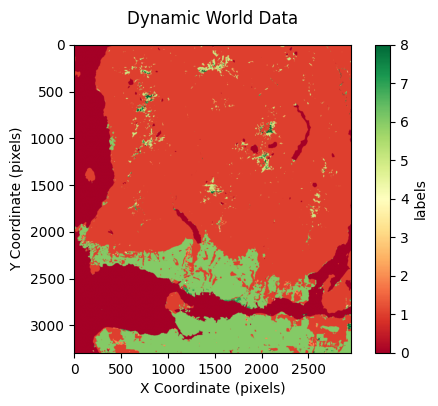

In [539]:
# Data visualization
plt.figure(figsize=(6, 4), dpi=100)
plt.imshow(dw_reproject, cmap="RdYlGn") 
plt.colorbar(label="labels")
plt.title("Dynamic World Data", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### Temporal NDVI Change Statistics

In [ ]:
# Ensure matching dataset shapes
print(
        f"NDVI 2024: {ndvi_crop[0].shape}\n"
        f"NDVI 2025: {ndvi_crop[1].shape}\n"
        f"NDVI 2026: {ndvi_crop[2].shape}\n"
        f"DW V1: {dw_crop.shape}\n"
        f"DEM Reproject: {elevation_crop.shape}\n"
        f"Slope: {slope_gdal_array.shape}\n"
)

In [ ]:
# Data visualization for NDVI, DEM, Slope, and DWV1
fig, axes = plt.subplots(1, 6, figsize=(16, 5), dpi=100, layout="constrained")
cmaps = ["RdYlGn", "RdYlGn", "RdYlGn", "terrain", "RdYlGn", "RdYlGn"]

datasets_full = [ndvi_crop[0], ndvi_crop[1], ndvi_crop[2], elevation_crop, slope_gdal_array, dw_crop]
labels_full = ["NDVI 2024","NDVI 2025","NDVI 2026", "Elevation (m)", "Slope (°)", "DW V1"]

for ax, labels_full, datasets_full, cmap in zip(axes, labels_full, datasets_full, cmaps):
    # Select dataset and specify axis labels
    im = ax.imshow(datasets_full, cmap=cmap)
    ax.set_title(labels_full, pad=15)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

plt.show()

In [ ]:
# Data statistics visualization
fig, axes = plt.subplots(2, 3, figsize=(15, 8), dpi=75, layout="constrained")
axes_flat = axes.flatten()

datasets_full = [ndvi_crop[0], ndvi_crop[1], ndvi_crop[2], elevation_crop, slope_gdal_array, dw_crop]
labels_full = ["NDVI 2024","NDVI 2025","NDVI 2026", "Elevation (m)", "Slope (°)", "DW V1"]

for i, (label, data_matrix) in enumerate(zip(labels_full, datasets_full)):
    # Compute statistics for the dataset
    v = data_matrix.ravel()[np.isfinite(data_matrix.ravel())]
    stats = [v.max(), v.min(), v.std(), v.mean(), np.median(v), skew(v)]
    print(f"{label} (Max, Min, Std, Mean, Med, Skew):", [round(x, 3) for x in stats])

    # Create histogram and set axis labels
    counts, bins, patches = axes_flat[i].hist(v, bins=50, color="green")
    axes_flat[i].set_title(f"{label} Statistics")
    max_bar_height = counts.max()
    axes_flat[i].set_ylim(0, max_bar_height * 1.3)

    # Specify text position and alignment 
    x_pos = 0.05 if i < 3 else 0.95
    h_align = 'left' if i < 3 else 'right'
    
    text = f"Max: {stats[0]:.2f}\nMin: {stats[1]:.2f}\nMean: {stats[3]:.2f}\nMed: {stats[4]:.2f}\nStd: {stats[2]:.2f}\nSkew: {stats[5]:.2f}"
    axes_flat[i].text(
        x_pos, 0.95, text, 
        transform=axes_flat[i].transAxes, 
        va='top', 
        ha=h_align, 
        bbox=dict(facecolor='white', alpha=0.7)
    )

plt.show()

In [ ]:
# Valid mask for NDVI temporal difference calculations
valid_ndvi_temporal = np.logical_and.reduce(
    [np.isfinite(ndvi) for ndvi in ndvi_crop]
)

# Function fro NDVI difference for date pairs
def diff_ndvi(start_date, end_date):
    difference = np.full(start_date.shape, np.nan, dtype=np.float32)
    np.subtract(end_date, start_date, out=difference, where=valid_ndvi_temporal)

    return difference

# Sorted date pairs by numerical index
date_pairs = sorted(
    combinations(range(len(ndvi_crop)), 2),
    key=lambda pair: pair[1] - pair[0],
)

# Compute NDVI differences for all date pairs
diff_ndvi_datasets = [
    diff_ndvi(ndvi_crop[start_date], ndvi_crop[end_date])
    for start_date, end_date in date_pairs
]

# Verify that the computed NDVI difference for 2024-2025 matches the expected result
diff_ndvi_2024_2025 = diff_ndvi(ndvi_crop[0], ndvi_crop[1])
np.array_equal(diff_ndvi_datasets[0], diff_ndvi_2024_2025, equal_nan=True)

In [ ]:
# NDVI difference visualization
fig, axes = plt.subplots(1, 3, figsize=(12, 6), dpi=75, layout="constrained")

temporal_labels = ["2024-2025 NDVI", "2025-2026 NDVI", "2024-2026 NDVI"]

for ax, temporal_labels, temporal_datasets in zip(axes, temporal_labels, diff_ndvi_datasets):
    # Select dataset and specify axis labels
    im = ax.imshow(temporal_datasets, cmap=cmap, vmin=-1, vmax=1) 
    ax.set_title(temporal_labels, pad=15)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

# Create overall colourbar for NDVI changes
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="vertical", shrink=0.7, pad=0.03)
cbar.set_label("NDVI Value")

plt.show()

In [ ]:
# NDVI difference statistics visualization
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=75, layout="constrained")
axes_flat = axes.flatten()

temporal_labels = ["2024–2025 NDVI", "2025–2026 NDVI", "2024–2026 NDVI"]

for i, (label, dataset) in enumerate(zip(temporal_labels, diff_ndvi_datasets)):
    # Compute statistics for the dataset
    v = dataset.ravel()[np.isfinite(dataset.ravel())]
    stats = [
        v.max(), v.min(), v.std(), v.mean(), np.median(v), skew(v),
        np.percentile(v, 5), np.percentile(v, 95)
    ]

    # Create histogram and set axis labels
    counts, bins, patches = axes_flat[i].hist(v, bins=50, color="green")
    axes_flat[i].set_title(f"{label} Statistics")
    axes_flat[i].set_xlabel("NDVI difference")
    axes_flat[i].set_ylabel("Pixel count")
    axes_flat[i].set_ylim(0, counts.max() * 1.3)

    # Store metadata for display onto the histogram
    text = (
        f"Max: {stats[0]:.2f}\n"
        f"Min: {stats[1]:.2f}\n"
        f"Mean: {stats[3]:.2f}\n"
        f"Med: {stats[4]:.2f}\n"
        f"Std: {stats[2]:.2f}\n"
        f"Skew: {stats[5]:.2f}\n"
        f"P05: {stats[6]:.2f}\n"
        f"P95: {stats[7]:.2f}"
    )

    axes_flat[i].text(
        0.05, 0.95, text,
        transform=axes_flat[i].transAxes,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", alpha=0.7)
    )

    # Verify that the computed statistics match the expected results
    print(
            f"{label} (Max, Min, Std, Mean, Med, Skew, P05, P95):",
            [round(x, 3) for x in stats]
    )

plt.show()

In [ ]:
# NDVI change statistics for all date pairs
t = 0  # NDVI change threshold

# Create empty dictionary to store statistics for each date pair
stats_by_pair = {}

# Loop through date pairs to calculate statistics
for (start, end), diff in zip(date_pairs, diff_ndvi_datasets):
    diff_values = diff[valid_ndvi_temporal]
    start_mean = np.mean(ndvi_all[start])
    end_mean = np.mean(ndvi_all[end])
    mean_change = np.mean(diff_values)
    valid_count = diff_values.size

    stats_by_pair[f"{years[start]} → {years[end]}"] = {
        "Start mean NDVI": start_mean,
        "End mean NDVI": end_mean,
        "Mean NDVI change": mean_change,
        "Percent change (%)": 100 * mean_change / start_mean,
        "Pixels increased": np.count_nonzero(diff_values > t),
        "Pixels decreased": np.count_nonzero(diff_values < t),
        "Pixels unchanged": np.count_nonzero(np.abs(diff_values) <= t),
        "Pixels increased (%)": 100 * np.count_nonzero(diff_values > t) / valid_count,
        "Pixels decreased (%)": 100 * np.count_nonzero(diff_values < t) / valid_count,
        "Pixels unchanged (%)": 100 * np.count_nonzero(np.abs(diff_values) <= t) / valid_count,
    }

# Convert dictionary to DataFrame for tabular results
ndvi_stats = pd.DataFrame.from_dict(stats_by_pair, orient="index")

ndvi_stats

In [ ]:
# Terrain correlation and pearson visualizations between years
comparisons = [(
    years[start], years[end], ndvi_crop[start], ndvi_crop[end]) 
    for start, end in date_pairs
]

# Data visualization for NDVI correlation and pearson coefficients
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=100, layout="constrained")

for ax, (year1, year2, ndvi1, ndvi2) in zip(axes, comparisons):
    # Select valid pixels for correlation adn compute Pearson correlation coefficient
    x = ndvi1[valid_ndvi_temporal] 
    y = ndvi2[valid_ndvi_temporal]
    P_coef = np.corrcoef(x, y)[0, 1]

    # Create hexbin plot for efficient visualization of large datasets
    hb = ax.hexbin(x, y, gridsize=100, mincnt=1, cmap="viridis")
    fig.colorbar(hb, ax=ax, label="Pixel count")

    # Set plot labels and features for Pearson correlation coefficients
    ax.plot([-1, 1], [-1, 1], "r:")
    ax.text(
        0.05, 0.95, f"Pearson r: {P_coef:.3f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="black", alpha=1),
    )
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_xlabel(f"{year1} NDVI")
    ax.set_ylabel(f"{year2} NDVI")
    ax.set_title(f"{year1} vs. {year2}")

    # Print Pearson correlation coefficient and number of valid pixels    
    print(f"Pearson correlation ({year1} vs. {year2}): {P_coef:.3f}")

plt.show()

In [ ]:
# Terrain correlation and pearson visualizations using 2026 NDVI for reference
comparisons = [
    ("Elevation (m)", "Slope (degrees)", elevation_crop, slope_gdal_array),
    ("2026 NDVI", "Elevation (m)", ndvi_crop[2], elevation_crop),
    ("2026 NDVI", "Slope (degrees)", ndvi_crop[2], slope_gdal_array),
]

valid_corr = (
    np.isfinite(elevation_crop)
    & np.isfinite(slope_gdal_array)
    & np.isfinite(ndvi_crop[2])
)

# Data visualization for terrain:slope:2026-NDVI correlation and pearson coefficients
fig, axes = plt.subplots(
    1, 3, figsize=(16, 5), dpi=150, layout="constrained"
)

for ax, (x_name, y_name, x_raster, y_raster) in zip(axes, comparisons):
    # Select valid pixels for correlation adn compute Pearson correlation coefficient
    x = x_raster[valid_corr]
    y = y_raster[valid_corr]
    P_coef = np.corrcoef(x, y)[0, 1]

    # Create hexbin plot for efficient visualization of large datasets
    hb = ax.hexbin(
        x, y, gridsize=100, mincnt=1, cmap="viridis"
    )

    # Set plot labels for Pearson correlation coefficients
    ax.text(
        0.05, 0.95, f"Pearson r: {P_coef:.3f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="black", alpha=1),
    )

    ax.set_xlabel(x_name)
    ax.set_ylabel(y_name)
    ax.set_title(f"{x_name} vs. {y_name}")
    fig.colorbar(hb, ax=ax, label="Pixel count")

    # Print Pearson correlation coefficient and number of valid pixels    
    print(
        f"Pearson correlation ({x_name} vs. {y_name}): "
        f"{P_coef:.3f} | Valid pixels: {len(x)}"
    )

plt.show()

#### K-Means Analysis

In [ ]:
# Create array to store reshaped NDVI datasets for K-Means clustering
ndvi_all = []

for ndvi_dataset in ndvi_crop:
    valid_ndvi_mask = ndvi_dataset[valid_ndvi_temporal]
    reshaped_ndvi = valid_ndvi_mask.reshape(-1, 1)

    print(
        f"NDVI dataset shape: {ndvi_dataset.shape}, "
        f"Valid pixels: {valid_ndvi_mask.size}, "
        f"Reshaped to: {reshaped_ndvi.shape}"
    )

    ndvi_all.append(reshaped_ndvi)

In [ ]:
# Run K-Means clustering on the reshaped NDVI datasets
model = KMeans(n_clusters=4, random_state=42, n_init="auto")
model.fit(ndvi_all)

In [ ]:
# Store cluster labels
cluster_maps = []

for ndvi_crop_dataset, reshaped_ndvi in zip(ndvi_crop, ndvi_all):
    cluster_map_array = np.full(ndvi_crop_dataset.shape, np.nan)

    cluster_map_array[valid_ndvi_temporal] = model.predict(reshaped_ndvi)
    cluster_maps.append(cluster_map_array)

In [ ]:
# Data visualization for K-Means clustering results
fig, axes = plt.subplots(1, 3, figsize=(15, 6), dpi=100)

for ax, year, cluster_map in zip(axes, years, cluster_maps):
    # Select dataset and specify axis labels
    im = ax.imshow(cluster_map, cmap="viridis", vmin=0, vmax=model.n_clusters - 1, interpolation="nearest")
    ax.set_title(f"{year} NDVI clusters")
    ax.axis("off")

# Create a colorbar for the cluster maps
fig.colorbar(
    im, ax=axes, ticks=range(model.n_clusters),
    label="K-means cluster", shrink=0.75
)

plt.show()

In [ ]:
# Get labels and cluster centers from model clusters
for label, center in enumerate(model.cluster_centers_.ravel()):
    print(f"Cluster {label}: center NDVI = {center:.3f}")

In [ ]:
# Create a valid mask for NDVI clusters
valid_ndvi_clusters = np.logical_and.reduce(
    [np.isfinite(cluster_map) for cluster_map in cluster_maps]
)

In [ ]:
# Store counts of pixels in each cluster for each year
counts_by_year = {
    year: np.bincount(
            cluster_map[valid_ndvi_clusters].astype(np.intp),
            minlength=model.n_clusters,
        )
    for year, cluster_map in zip(years, cluster_maps)
}

# Compute percent change between years for each cluster
percent_change_by_pair = {
    f"{start_year}-{end_year} % Change": np.divide(
        counts_by_year[end_year] - counts_by_year[start_year],
        counts_by_year[start_year],
        out=np.full(model.n_clusters, np.nan),
        where=counts_by_year[start_year] != 0,
    ) * 100
    for start_year, end_year in date_pairs
}

# Store dictionaries in a DataFrame for tabular results
cluster_counts = pd.DataFrame(
    {**counts_by_year, **percent_change_by_pair},
    index=[f"Cluster {i}" for i in range(model.n_clusters)],
)

# Create colour change for DataFrame display based on percent change values
def color_change(value):
    if pd.isna(value) or value == 0:
        return ""
    return "background-color: #d9534f; color: white;" if value < 0 else "background-color: #5cb85c; color: white;"

target_cols = ["2024-2025 % Change", "2025-2026 % Change", "2024-2026 % Change"]

cluster_counts
cluster_counts.style.map(
    color_change,
    subset=target_cols,
).format(
    lambda x: f"{abs(x):.2f}%" if pd.notna(x) else "", # report negative values as positive for percent change, keeping colour coding
    subset=target_cols
)

#### K-means Clustering Correlation

In [ ]:
# Create features matrix for K-Means clustering using NDVI, DEM, and slope data
features = np.stack(
    [
        ndvi_crop[0],
        ndvi_crop[1],
        ndvi_crop[2],
        elevation_crop,
        slope_gdal_array
    ],
    axis = -1
)

# Create a valid mask for features to ensure all values are finite
valid_mask_features = np.all(np.isfinite(features), axis=-1)
finite_training_features = features[valid_mask_features]

# Standardize the features using StandardScaler
scaler = StandardScaler()
features_scaled = scaler.fit_transform(finite_training_features)

# Verify training features and standardized features shapes
print(
    f"Finite training features shape: {finite_training_features.shape}\n"
    f"Standardized features shape: {features_scaled.shape}"
)

In [ ]:
# Run K-Means clustering on the standardized features
model_cluster_corr = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

In [ ]:
# Store cluster labels for each pixel in the valid mask
cluster_labels = model_cluster_corr .fit_predict(features_scaled)

cluster_map = np.full(
    valid_mask_features.shape,
    np.nan,
    dtype=np.float32
)

cluster_map[valid_mask_features] = cluster_labels

In [ ]:
# Invert standardization to get cluster centers in original units
centres_cluster_corr = scaler.inverse_transform(model_cluster_corr.cluster_centers_)

# Prepare DataFrame for cluster centers and correlation statistics
feature_names = [
    "NDVI 2024", "NDVI 2025", "NDVI 2026",
    "Elevation (m)", "Slope (degrees)"
]

cluster_centres_df = pd.DataFrame(
    centres_cluster_corr, 
    columns=feature_names,
    index=[f"Cluster {i}" for i in range(model_cluster_corr.n_clusters)],
)

cluster_centres_df

In [ ]:
# Create datframe for correlation analysis and compute Pearson correlation coefficients
df_corr = pd.DataFrame(finite_training_features, columns=feature_names)
df_corr["Cluster"] = cluster_labels
pearson_corr = df_corr[feature_names].corr(method="pearson")

display(pearson_corr.round(3))

In [ ]:
# Create sample of pixels for correlation analysis to avoid overplotting in pairplot
cluster_corr_data = df_corr.sample(
    n=min(5000, len(df_corr)),
    random_state=42,
)

# Create pairplot for correlation analysis with cluster labels
corr_plots = sns.pairplot(
    cluster_corr_data,
    vars=feature_names,
    hue="Cluster",
    corner=True,
    height=2,
    aspect=1.5,
    plot_kws={"alpha": 0.35, "s": 8},
    diag_kind="hist",
)

# Loop over pairplots to annotate Pearson correlation coefficients
for i, j in zip(*np.tril_indices(len(feature_names), k=-1)):
    corr = cluster_corr_data[feature_names].corr(method="pearson")
    ax = corr_plots.axes[i, j]
    r = corr.iloc[i, j]

    ax.annotate(
        f"r = {r:.2f}",
        xy=(0.05, 0.95),
        xycoords="axes fraction",
        ha="left",
        va="top",
        fontsize=9,
        bbox=dict(
        facecolor="white",
        alpha=0.8,
        edgecolor="none"
        )
    )
    
plt.show()

### RandomForest Classification against Dynamic World V1 **

### Band and Blender Exports

In [ ]:
# Create shared validity mask for all datasets
valid_mask_export = (
    np.isfinite(elevation_crop)
    & np.isfinite(slope_gdal_array)
    & np.isfinite(ndvi_crop[0])
    & np.isfinite(ndvi_crop[1])
    & np.isfinite(ndvi_crop[2])
)

# Extract rows and columns of valid pixels
rows, cols = np.where(valid_mask_export)
crop_transform = sentinel_transform * Affine.translation(col0, row0)

x_coords, y_coords = rasterio.transform.xy(crop_transform, rows, cols, offset='center')

# Prepare clean datasets into dictionaries for bulk point conversion
clean_data = {
    "x_clean": x_coords,
    "y_clean": y_coords,
    "z_clean": elevation_crop[rows, cols],
    "slope_clean": slope_gdal_array[rows, cols],
    "ndvi_2024_clean": (ndvi_crop[0])[rows, cols],
    "ndvi_2025_clean": (ndvi_crop[1])[rows, cols],
    "ndvi_2026_clean": (ndvi_crop[2])[rows, cols],
}

# Shift points to Blender origin
origin_points = {
    key: (
        (clean_data[key].min() + clean_data[key].max()) / 2 # use midpoint to shift to origin
        if key in ("x_clean", "y_clean")
        else clean_data[key].min() # minimum values close to origin for z, slope, and NDVI
    )
    for key in clean_data # reuses keys from clean_data
}

shifted_points = {
    key: (
        (clean_data[key] - origin_points[key])
    )
    for key in clean_data
}

# Scale points for visual scene scaling in Blender
scale = 100.0

scaled_points = {
    key: (
        (clean_data[key] - origin_points[key]) / scale # shift points and scale all datasets by same factor
    )
    for key in clean_data
}

In [ ]:
np.max(clean_data["z_clean"])
np.max(clean_data["slope_clean"])

In [ ]:
# Verify scaled points dictionary values match blender export points 
print("Scaled Points:")
for name, values in scaled_points.items():
    print(f"{name}: {values[:5]}")

print("\nBlender Points:")
for i, column in enumerate(blender_points.T):
    print(f"Column {i}: {column[:5]}")

In [ ]:
# Prepare scaled points for Blender export
blender_points = []

for values in clean_data.values():
    blender_points.append(values)

blender_points = np.column_stack(blender_points)

np.savetxt(
    r"Data Export\terrain_points.csv",
    blender_points,
    delimiter=",",
    header="x_pos_bld,y_pos_bld,z_elev_bld,slope_degrees,ndvi_2024,ndvi_2025,ndvi_2026",
    comments="",
)

### Multi-band Export to QGIS

In [ ]:
# Store bands for export into dictionary
clean_export_datasets = {
    "NDVI_2024": ndvi_crop[0],
    "NDVI_2025": ndvi_crop[1],
    "NDVI_2026": ndvi_crop[2],
    "DEM": elevation_crop,
    "Slope": slope_gdal_array,
    "DW_v1": dw_crop
}

# Verify clean export bands have matching shapes
for name, array in clean_export_datasets.items():
    print(f"Key: {name}, Array Shape: {array.shape}")

# Select width and height of export datasets
export_array_width, export_array_height = clean_export_datasets["NDVI_2024"].shape[1], clean_export_datasets["NDVI_2024"].shape[0]

In [ ]:
# Specify export path and crop the grid transform to match the cropped datasets
output_path = r"Data Export\export_bands.tif"
crop_transform = sentinel_transform * Affine.translation(col0, row0)

# Export clean datasets to GeoTIFF
with rasterio.open(output_path, "w",
                   driver="GTiff",
                   height=export_array_height,
                   width=export_array_width,
                   count=len(clean_export_datasets),
                   dtype="float32",
                   crs=sentinel_crs,
                   transform=crop_transform,
                   nodata=np.nan) as dst:

    for band_number, (name, raster) in enumerate(clean_export_datasets.items(), start=1):
        dst.write(raster.astype("float32"), band_number)
        dst.set_band_description(band_number, name)

# Missed **

- zenith, solar angle, shadow
- zero values for ndvi filter? 
- bug check, top down load check
- fix temporal correlation first charts, not kmeans, maybe use pd there
- aspect
- hillshade

In [ ]:
# --- settings ---
step = 1          # 1 = every pixel (matches the TIF); 2 = thin to a quarter of the points
z_shift = 0.0     # 0.0 keeps true elevations; use elev.min() later if you want the lowest point at z=0

# --- thin every array with the same slice so they stay aligned ---
elev    = elevation_crop[::step, ::step]
slope   = slope_gdal_array[::step, ::step]
ndvi_24 = ndvi_crop[0][::step, ::step]
ndvi_25 = ndvi_crop[1][::step, ::step]
ndvi_26 = ndvi_crop[2][::step, ::step]

# --- shared validity mask ---
valid = (
    np.isfinite(elev) & np.isfinite(slope)
    & np.isfinite(ndvi_24) & np.isfinite(ndvi_25) & np.isfinite(ndvi_26)
)
rows, cols = np.where(valid)

# --- pixel -> UTM (multiply by step to recover the original pixel positions) ---
crop_transform = sentinel_transform * Affine.translation(col0, row0)
x_utm, y_utm = rasterio.transform.xy(crop_transform, rows * step, cols * step, offset="center")
x_utm, y_utm = np.asarray(x_utm), np.asarray(y_utm)

# --- origin = upper-left corner of the crop, so the cloud lines up with the TIF ---
origin_x, origin_y = crop_transform * (0, 0)

# --- one dict drives both the header and the columns ---
blender_points = {
    "x_pos_bld":     x_utm - origin_x,
    "y_pos_bld":     y_utm - origin_y,
    "z_elev_bld":    elev[rows, cols] - z_shift,
    "slope_degrees": slope[rows, cols],
    "ndvi_2024":     ndvi_24[rows, cols],
    "ndvi_2025":     ndvi_25[rows, cols],
    "ndvi_2026":     ndvi_26[rows, cols],
}

# --- quick checks before writing ---
for name in ("x_pos_bld", "y_pos_bld", "z_elev_bld"):
    arr = blender_points[name]
    print(f"{name}: min={arr.min():.1f}  max={arr.max():.1f}  span={arr.max()-arr.min():.1f}")
print("points:", len(rows))

# --- write last ---
np.savetxt(
    r"Data Export\terrain_points.csv",
    np.column_stack(list(blender_points.values())),
    delimiter=",",
    header=",".join(blender_points),
    comments="",
    fmt="%.3f",
)

In [ ]:
from pathlib import Path
import time

csv_path = Path(r"Data Export\terrain_points.csv")   # use this same variable in np.savetxt(csv_path, ...)

# --- read back what is actually on disk ---
written = pd.read_csv(csv_path)
print("file:    ", csv_path.resolve())
print("size MB: ", round(csv_path.stat().st_size / 1e6, 1))
print("modified:", time.ctime(csv_path.stat().st_mtime))
print(written[["x_pos_bld", "y_pos_bld", "z_elev_bld"]].agg(["min", "max"]))

x_span = written["x_pos_bld"].max() - written["x_pos_bld"].min()
y_span = written["y_pos_bld"].max() - written["y_pos_bld"].min()
print(f"x span = {x_span:.0f} m, y span = {y_span:.0f} m")

# --- expected from the crop: narrow in x (~10.4 km), tall in y (~24.9 km), y running negative ---
assert x_span < y_span, "x is longer than y: the columns or the transform are swapped"
assert written["x_pos_bld"].min() >= -1, "x should start at 0 or above"
assert written["y_pos_bld"].max() <= 1, "y should be 0 or below"